# Tracking plants over time with SAM3, seeded by hand-drawn polygons

Takes a range of frames from the CanopyMap dataset, undistorts them, and tracks plants through all of them with SAM3. The seeds are **your hand-drawn polygons** (a COCO json such as `plants.json`, or polygons typed in directly) placed on the start frame. No detector is involved: only the plants you outlined are tracked, and each keeps its id for the whole run.

Outputs: an overlay video and a `tracks.jsonl` with one polygon per plant per frame.

**Important:** the polygons must have been drawn on (or match) the frame you set as `START_IDX`, in undistorted pixel coordinates.

## Install

The pinned `transformers` build is the one with the SAM3 video tracker. Restart the runtime after this cell.

In [1]:
%pip install "segment-geospatial[samgeo3]==1.4.2"
%pip install transformers==5.0.0rc0 av defisheye
!git clone https://github.com/regularpooria/CanopyMap.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of anyio to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of pydantic to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 108.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 732.8/732.8 kB 32.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.4/24.4 MB 59.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 89.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 78.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 77.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 44.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1

## Login and load the dataset

In [2]:
from google.colab import userdata
from huggingface_hub import login
from datasets import load_dataset

login(token=userdata.get("HF_KEY"))
ds = load_dataset("regularpooria/canopymap_plants")["train"]
print(ds)

README.md:   0%|          | 0.00/637 [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  507MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  378MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  405MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3163 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'channel', 'date', 'time', 'suitable', 'ph_boxes_xyxy', 'ph_conf', 'ph_cls', 'ph_polygons'],
    num_rows: 3163
})


## Settings

`STOP_IDX` is exclusive, like a Python range. `CHUNK` is how many frames go through SAM3 at once; each chunk is handed the last masks of the previous one so ids carry across. Lower it if you run out of memory on the T4.

- `ANN_FILE`: COCO json with your polygons (`segmentation`). Each annotation becomes one tracked plant, using the annotation `id` as the plant id.
- `INLINE_POLYGONS`: set this instead if you'd rather type polygons by hand (list of polygons, each a list of `[x, y]`). Leave `None` to use the json.
- `POLY_SIZE`: `(width, height)` of the image the polygons were drawn on. Leave `None` to read it from the json. Polygons are rescaled if the start frame has a different size.
- `SEED_WITH`: `"masks"` seeds SAM3 with the exact polygon shapes, `"boxes"` seeds with each polygon's bounding box and lets SAM3 segment inside it.

In [3]:
from pathlib import Path

START_IDX = 100
STOP_IDX = 1000
CHUNK = 150
FPS = 3

ANN_FILE = "plan.json"
INLINE_POLYGONS = None
# INLINE_POLYGONS = [
#     [[329, 854], [409, 819], [554, 901], [451, 611], [347, 644], [259, 770]],
#     [[638, 555], [612, 511], [557, 512], [521, 547], [606, 620], [666, 676]],
# ]
POLY_SIZE = None           # e.g. (1920, 1920)
SEED_WITH = "masks"        # "masks" or "boxes"

WORK_DIR = Path("work");    WORK_DIR.mkdir(exist_ok=True)
OUT_DIR  = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
VIDEO_PATH  = OUT_DIR / "tracked.mp4"
TRACKS_PATH = OUT_DIR / "tracks.jsonl"

## Upload the annotations (Colab only)

Skip this cell if the json is already on disk or you use `INLINE_POLYGONS`.

In [ ]:
from google.colab import files
uploaded = files.upload()   # pick plants.json
print(list(uploaded))

## Loading and undistorting frames

Same fisheye correction as the detection notebook. `de_fish_eye_image` wants a file path, so each frame takes a quick trip through a temp jpg. Frames come back as RGB arrays.

In [4]:
import cv2
import numpy as np
from tqdm.auto import tqdm
from CanopyMap.src.utils.distortion import de_fish_eye_image

def undistort(i):
    tmp = WORK_DIR / "tmp.jpg"
    ds[i]["image"].convert("RGB").save(tmp)
    return cv2.cvtColor(de_fish_eye_image(str(tmp)), cv2.COLOR_BGR2RGB)

def load_frames(start, stop):
    return np.stack([undistort(i) for i in tqdm(range(start, stop), desc="undistort", leave=False)])

start_frame = load_frames(START_IDX, START_IDX + 1)[0]
H0, W0 = start_frame.shape[:2]
print("start frame:", W0, "x", H0)

undistort:   0%|          | 0/1 [00:00<?, ?it/s]

start frame: 1920 x 1920


## Turn the hand-drawn polygons into seeds

Each COCO annotation becomes one plant (if it has several rings, the largest is used). Polygons are rescaled to the start frame if their source size differs, then rasterised into full-frame masks and bounding boxes. Plants are numbered by annotation id.

In [5]:
import json

def shoelace(p):
    x, y = p[:, 0], p[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))

polygons, ids = [], []
src_size = POLY_SIZE

if INLINE_POLYGONS is not None:
    polygons = [np.asarray(p, dtype=np.float32).reshape(-1, 2) for p in INLINE_POLYGONS]
    ids = list(range(1, len(polygons) + 1))
else:
    with open(ANN_FILE) as f:
        coco = json.load(f)
    if src_size is None and coco.get("images"):
        src_size = (coco["images"][0]["width"], coco["images"][0]["height"])
    for ann in coco["annotations"]:
        seg = ann.get("segmentation")
        if not isinstance(seg, list) or not seg:
            print(f"annotation {ann['id']}: no polygon (RLE not supported), skipped")
            continue
        rings = [np.asarray(r, dtype=np.float32).reshape(-1, 2) for r in seg]
        polygons.append(max(rings, key=shoelace))
        ids.append(int(ann["id"]))

assert polygons, "no polygons loaded"
assert len(set(ids)) == len(ids), "annotation ids are not unique"

if src_size is not None and tuple(src_size) != (W0, H0):
    sx, sy = W0 / src_size[0], H0 / src_size[1]
    print(f"polygons drawn on {src_size[0]}x{src_size[1]}, start frame is {W0}x{H0}: rescaling by ({sx:.3f}, {sy:.3f})")
    if abs(sx - sy) > 0.01:
        print("WARNING: aspect ratio differs, the polygons are probably from a different crop. Check the preview below.")
    polygons = [p * np.array([sx, sy], dtype=np.float32) for p in polygons]

def poly_to_mask(poly, h, w):
    m = np.zeros((h, w), np.uint8)
    cv2.fillPoly(m, [np.round(poly).astype(np.int32)], 1)
    return m.astype(bool)

seed_masks = [poly_to_mask(p, H0, W0) for p in polygons]
boxes = [[float(p[:, 0].min()), float(p[:, 1].min()), float(p[:, 0].max()), float(p[:, 1].max())] for p in polygons]
print(f"{len(ids)} seed plant(s), ids: {ids}")
for pid, m in zip(ids, seed_masks):
    if m.sum() == 0:
        print(f"WARNING: plant {pid} has an empty mask (polygon outside the frame?)")

9 seed plant(s), ids: [1, 2, 3, 4, 5, 6, 7, 8, 9]


## Check the seeds on the start frame

Worth a look before the long run. If the polygons don't sit on the plants, `START_IDX` is probably not the frame they were drawn on, or `POLY_SIZE` is wrong.

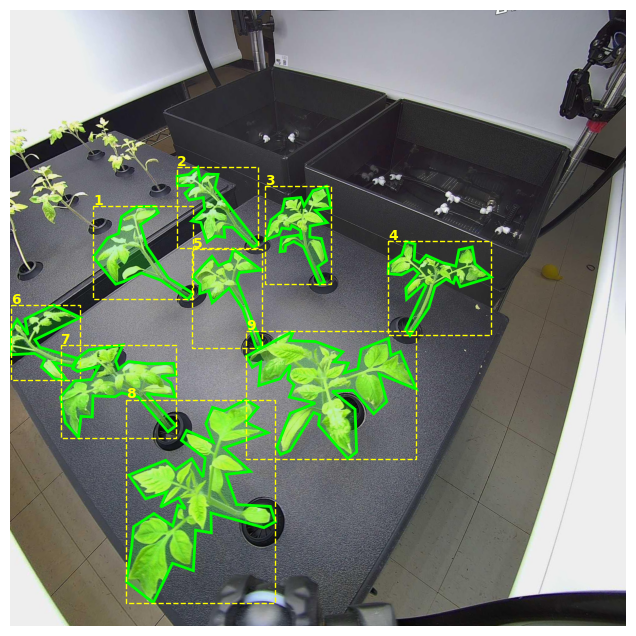

In [6]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(start_frame)
for pid, poly, (x1, y1, x2, y2) in zip(ids, polygons, boxes):
    ax.add_patch(patches.Polygon(poly, fill=True, facecolor=(0, 1, 0, 0.2), edgecolor="lime", linewidth=2))
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="yellow", linewidth=1, linestyle="--"))
    ax.text(x1, y1 - 4, str(pid), color="yellow", weight="bold")
ax.axis("off")
plt.show()

## Load SAM3

This is the tracker variant, which takes box or mask prompts tied to an object id. fp16 because the T4 has no real bf16 support.

In [7]:
import torch
from transformers import Sam3TrackerVideoModel, Sam3TrackerVideoProcessor

DEVICE, DTYPE = "cuda", torch.float16
model = Sam3TrackerVideoModel.from_pretrained("facebook/sam3").to(DEVICE, dtype=DTYPE).eval()
processor = Sam3TrackerVideoProcessor.from_pretrained("facebook/sam3")

config.json:   0%|          | 0.00/25.8k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/845 [00:00<?, ?it/s]

processor_config.json:   0%|          | 0.00/1.71k [00:00<?, ?B/s]

## Output helpers

Masks are drawn onto the frame with the plant id, and each mask is also reduced to a simplified polygon plus bbox and area for `tracks.jsonl`. The video is written frame by frame so nothing piles up in memory.

In [8]:
import av

def color_for(pid):
    hsv = np.uint8([[[int(((pid * 0.618) % 1.0) * 179), 220, 255]]])
    return tuple(int(c) for c in cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)[0, 0])

def draw_tracks(frame, masks, ids, alpha=0.45):
    out = frame.copy()
    scale = frame.shape[0] / 1080
    for m, pid in zip(masks, ids):
        if not m.any():
            continue
        color = color_for(pid)
        out[m] = (out[m] * (1 - alpha) + np.array(color) * alpha).astype(np.uint8)
        cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cnts, -1, color, 2)
        ys, xs = np.nonzero(m)
        cv2.putText(out, str(pid), (int(xs.mean()), int(ys.mean())),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.2 * scale, (255, 255, 255), max(2, int(3 * scale)))
    return out

def mask_to_track(m, pid):
    cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    poly = cv2.approxPolyDP(max(cnts, key=cv2.contourArea), 1.5, True)[:, 0]
    x, y, w, h = cv2.boundingRect(poly)
    return {"id": int(pid), "area": int(m.sum()), "bbox": [x, y, x + w, y + h],
            "polygon": poly.round(1).tolist()}

def open_writer(path, w, h, fps):
    container = av.open(str(path), mode="w")
    stream = container.add_stream("libx264", rate=fps)
    stream.width, stream.height = w - w % 2, h - h % 2
    stream.pix_fmt = "yuv420p"
    stream.options = {"crf": "20"}
    return container, stream

def write_frame(container, stream, frame):
    frame = np.ascontiguousarray(frame[:stream.height, :stream.width])
    for p in stream.encode(av.VideoFrame.from_ndarray(frame, format="rgb24")):
        container.mux(p)

## Track every frame

The first chunk is seeded with your hand-drawn polygons (as masks or boxes, see `SEED_WITH`) under their annotation ids. Every later chunk is seeded with each plant's most recent mask, so the id follows the same plant across chunk boundaries. Per frame we write the overlay and the polygons, then free the chunk before loading the next.

In [9]:
import gc

last_mask = {}
container = stream = None

with open(TRACKS_PATH, "w") as tracks_f, torch.inference_mode(), torch.autocast("cuda", dtype=DTYPE):
    for c_start in range(START_IDX, STOP_IDX, CHUNK):
        c_stop = min(c_start + CHUNK, STOP_IDX)
        frames = load_frames(c_start, c_stop)
        H, W = frames.shape[1:3]
        if container is None:
            container, stream = open_writer(VIDEO_PATH, W, H, FPS)

        session = processor.init_video_session(
            video=frames, inference_device=DEVICE, processing_device="cpu",
            video_storage_device="cpu", dtype=DTYPE,
        )
        if c_start == START_IDX:
            if SEED_WITH == "masks":
                processor.add_inputs_to_inference_session(
                    session, frame_idx=0, obj_ids=ids, input_masks=seed_masks)
            else:
                processor.add_inputs_to_inference_session(
                    session, frame_idx=0, obj_ids=ids, input_boxes=[boxes])
        else:
            processor.add_inputs_to_inference_session(
                session, frame_idx=0, obj_ids=list(last_mask), input_masks=list(last_mask.values()))

        for out in tqdm(model.propagate_in_video_iterator(session, start_frame_idx=0), total=len(frames), desc=f"frames {c_start}-{c_stop - 1}"):
            logits = processor.post_process_masks([out.pred_masks], original_sizes=[[H, W]], binarize=False)[0]
            masks = (logits[:, 0] > 0).cpu().numpy()

            tracks = []
            for m, pid in zip(masks, out.object_ids):
                if m.any():
                    last_mask[int(pid)] = m
                    tracks.append(mask_to_track(m, pid))
            tracks_f.write(json.dumps({"frame": c_start + out.frame_idx, "tracks": tracks}) + "\n")
            write_frame(container, stream, draw_tracks(frames[out.frame_idx], masks, out.object_ids))

        del session, frames
        gc.collect()
        torch.cuda.empty_cache()

for p in stream.encode():
    container.mux(p)
container.close()
print("done:", VIDEO_PATH, TRACKS_PATH)

undistort:   0%|          | 0/150 [00:00<?, ?it/s]

frames 100-249:   0%|          | 0/150 [00:00<?, ?it/s]

undistort:   0%|          | 0/150 [00:00<?, ?it/s]

frames 250-399:   0%|          | 0/150 [00:00<?, ?it/s]

undistort:   0%|          | 0/150 [00:00<?, ?it/s]

frames 400-549:   0%|          | 0/150 [00:00<?, ?it/s]

... (3 outputs left out)

frames 700-849:   0%|          | 0/150 [00:00<?, ?it/s]

undistort:   0%|          | 0/150 [00:00<?, ?it/s]

frames 850-999:   0%|          | 0/150 [00:00<?, ?it/s]

done: outputs/tracked.mp4 outputs/tracks.jsonl


In [10]:
from google.colab import files
files.download(str(VIDEO_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Results

Quick look at the overlay video, plus how many frames each plant id was actually found in. An id with low coverage usually means the tracker lost that plant, or it was occluded.

In [ ]:
from collections import Counter
from IPython.display import Video

seen = Counter()
with open(TRACKS_PATH) as f:
    n_frames = 0
    for line in f:
        n_frames += 1
        seen.update(t["id"] for t in json.loads(line)["tracks"])

for pid in ids:
    print(f"plant {pid:>2}: found in {seen[pid]}/{n_frames} frames")

Video(str(VIDEO_PATH), embed=True, width=720)